# 02 – Passmodell: vom ersten Modell zum Zonenmodell (Aufgabe 1)

**Ziel:** Für jeden Pass die Wahrscheinlichkeit schätzen, dass er ankommt (xPass). Grundlage sind nur die Event-Daten.

**Weg:** Wir starten mit einem einfachen Modell und nehmen Schritt für Schritt Merkmale dazu. Wo das einfache Modell systematisch danebenliegt, verfeinern wir es zum Zonenmodell (Hauptmodell).

| Entscheidung | Wahl | Begründung |
|---|---|---|
| Pass | alle Zuspiele mit dem Fuß, ohne Einwürfe, Ecken, Anstöße | Einwurf = Hand, Ecke ≈ Torchance, Anstoß trivial (Notebook 01) |
| Erfolg | DFL-Bewertung (`successfullyCompleted`, `successful`) | offizielle Bewertung, stimmt mit kloppys Ergebnis fast vollständig überein (Notebook 01) |
| Empfänger bei Fehlpässen unbekannt | Richtung statt Ziel | die Richtung ist auch bei Fehlpässen bekannt |
| Ausgeschlossen | Endpunkt, DFL-Länge, DFL-Passart, Empfänger | Leakage (Notebook 01) |
| Modell | logistische Regression | liefert Wahrscheinlichkeiten, ist interpretierbar, passt zur Datenmenge (5.664 Pässe) |
| Bewertung | Leave-one-match-out | jedes Spiel wird von einem Modell vorhergesagt, das dieses Spiel nicht kennt |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.patches import Rectangle
from mplsoccer import Pitch
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score


ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from modell import (DRITTEL_GRENZE, STRAFRAUM_X, STRAFRAUM_Y, leave_one_match_out, modell_a_merkmale,
                    pass_auswahl, zone, zonen_merkmale)
from passdaten import lade_pass_tabelle

# erzeugte Pass-Tabelle aus Notebook 01 laden
d = pass_auswahl(lade_pass_tabelle(ROOT / "data" / "paesse.csv"))
y = d["erfolg"].to_numpy()          # Zielgröße: 1 = angekommen, 0 = nicht angekommen
spiele = d["match_id"]              # Spiel jedes Passes, für Leave-one-match-out evaluation
print(f"{len(d)} Pässe, davon {y.mean():.1%} erfolgreich")

5664 Pässe, davon 78.6% erfolgreich


Koordinaten (aus `passdaten.py`): Meter, das passende Team greift immer nach rechts an. x ist die Längsachse (0 = Mittellinie, +52,5 = gegnerische Torlinie), y die Querachse (0 = Mitte, positiv = links).

## 1. Erster Blick ohne Modell

Wie hängen Richtung und Höhe mit dem Erfolg zusammen? (Erfolgsquote je Gruppe)

In [2]:
# Richtung grob einteilen, dann Erfolgsquote je Richtung und Höhe
richtung = pd.cut(np.cos(np.radians(d["play_angle"])), [-1.01, -0.5, 0.5, 1.01], labels=["zurück", "quer", "nach vorn"])
pd.crosstab(richtung, d["hoehe"], values=d["erfolg"], aggfunc="mean").round(3)

hoehe,flat,high
play_angle,,
zurück,0.955,0.741
quer,0.928,0.537
nach vorn,0.842,0.451


Hohe Bälle kommen viel seltener an als flache, Pässe nach vorn seltener als Rückpässe. Beides gehört ins Modell.

## 2. Erstes Modell A: Ort als Gerade

| Merkmal | Bedeutung |
|---|---|
| `x_10m` | wie weit vorn gespielt wird, in 10 m (0 = Mittellinie, +5 = gegnerische Torlinie) |
| `abstand_mitte_10m` | wie weit außen, in 10 m (0 = Mitte, 3,4 = Seitenlinie) |
| `flanke`, `freistoss`, `abstoss` | Art bzw. Situation (0/1) |
| `hoch` | hoher Ball laut DFL (0/1) |
| `tiefe` | cos θ: +1 = genau in die Tiefe, 0 = quer, −1 = genau zurück (θ = DFL-Abspielwinkel, 0° = Richtung gegnerisches Tor) |
| `breite` | \|sin θ\|: 0 = gerade, 1 = genau quer |

Warum `tiefe` und `breite` statt eines Winkels in Grad? Bei einem Winkel lägen 359° und 1° für das Modell weit auseinander, obwohl beide fast geradeaus nach vorn sind. Kosinus und Sinus haben dieses Problem nicht.

**Bewertung (Leave-one-match-out):** 7-mal wird auf 6 Spielen trainiert und das 7. Spiel vorhergesagt. Verglichen wird mit einer Baseline, die jedem Pass die durchschnittliche Erfolgsquote der Trainingsspiele gibt.
- **Log-Loss:** durchschnittliche Strafe für Fehleinschätzungen; bestraft vor allem sichere, aber falsche Vorhersagen (kleiner ist besser). Hauptkriterium, weil es um gute Wahrscheinlichkeiten geht.
- **Brier-Score:** mittlere quadratische Abweichung zwischen Wahrscheinlichkeit und Ergebnis (kleiner ist besser).
- **AUC:** Wahrscheinlichkeit, dass ein zufälliger angekommener Pass einen höheren Wert bekommt als ein zufälliger Fehlpass (0,5 = Raten, 1 = perfekt). Beschreibt wie gut das Modell Pass/Fehlpass trennen kann.

Wir bauen das Modell schrittweise auf, um zu sehen, was jede Merkmalsgruppe bringt.

In [3]:
X_a = modell_a_merkmale(d)          # die 8 Merkmale von Modell A (modell.py)

# Baseline ohne Modell: jeder Pass bekommt die Erfolgsquote der anderen 6 Spiele
p_baseline = np.zeros(len(y))
for m in spiele.unique():
    p_baseline[(spiele == m).to_numpy()] = y[(spiele != m).to_numpy()].mean()

# Schritt für Schritt mehr Merkmale: erst Ort + Situation, dann Richtung, dann Höhe
schritte = {
    "Ort + Situation": ["x_10m", "abstand_mitte_10m", "flanke", "freistoss", "abstoss"],
    "+ Richtung": ["x_10m", "abstand_mitte_10m", "flanke", "freistoss", "abstoss", "tiefe", "breite"],
    "+ Höhe (= Modell A)": list(X_a.columns),
}
vorhersagen = {"Baseline": p_baseline}
for name, spalten in schritte.items(): # für jeden schritt ein modell trainieren und vorhersagen
    vorhersagen[name] = leave_one_match_out(X_a[spalten], y, spiele)  # 7-mal auf 6 Spielen trainieren und das 7. Spiel vorhersagen


def guete(vorhersagen):
    # Log-Loss, Brier-Score und AUC je Modell (die Baseline trennt nicht, deshalb AUC = 0,5)
    return pd.DataFrame({
        name: {"Log-Loss": log_loss(y, p), "Brier": brier_score_loss(y, p),
               "AUC": roc_auc_score(y, p) if name != "Baseline" else 0.5}
        for name, p in vorhersagen.items()
    }).T.round(4)


guete(vorhersagen)

,Log-Loss,Brier,AUC
Baseline,0.5210,0.1688,0.5000
Ort + Situation,0.5032,0.1612,0.5771
+ Richtung,0.4437,0.1444,0.7650
+ Höhe (= Modell A),0.3900,0.1246,0.8364


Ort und Situation allein trennen kaum (AUC 0,58). Die Richtung bringt den größten Sprung (AUC 0,77), die Höhe den zweitgrößten (AUC 0,84). Der Log-Loss sinkt von 0,521 auf 0,390.

### Brauchen Flanken, Freistöße und Abstöße ein eigenes Kennzeichen?

Vergleich: Modell A mit Kennzeichen gegen dasselbe Modell ohne die drei Kennzeichen. Tatsächliche Erfolgsquote und mittlere Vorhersage je Gruppe:

In [4]:
# Dasselbe Modell A noch einmal, aber ohne die Kennzeichen für Flanke, Freistoß und Abstoß
ohne_kennzeichen = leave_one_match_out(X_a.drop(columns=["flanke", "freistoss", "abstoss"]), y, spiele)
offenes_spiel = (d["standard"] == "OPEN_PLAY") & ~d["flanke"]
gruppe = np.where(offenes_spiel, "Pass aus dem Spiel", np.where(d["flanke"], "Flanke", d["standard"]))
vergleich = pd.DataFrame({"tatsächlich": y, "mit Kennzeichen": vorhersagen["+ Höhe (= Modell A)"],
                          "ohne Kennzeichen": ohne_kennzeichen})
tabelle = vergleich.groupby(gruppe).mean()
tabelle.insert(0, "Pässe", vergleich.groupby(gruppe).size())
tabelle.round(3)

,Pässe,tatsächlich,mit Kennzeichen,ohne Kennzeichen
FREE_KICK,156,0.737,0.727,0.689
Flanke,152,0.283,0.288,0.397
GOAL_KICK,117,0.718,0.729,0.807
Pass aus dem Spiel,5239,0.803,0.803,0.799


- Ohne Kennzeichen überschätzt das Modell Flanken (40 % statt 28 %) und Abstöße (81 % statt 72 %). In der Spielerauswertung sähen Außenspieler und Torhüter dann systematisch schlecht aus.
- Für normale Pässe aus dem Spiel ändert sich fast nichts (80,3 % gegenüber 79,9 %); die Sonderfälle sind nur 7,5 % der Pässe.

**Entscheidung:** Kennzeichen bleiben. Flanken werden damit an Flanken gemessen, Abstöße an Abstößen, hohe Bälle an hohen Bällen. „Angekommene minus erwartete Pässe“ misst also die **Ausführung**, nicht die **Entscheidung**, ob man diese Art von Pass überhaupt spielt.

## 3. Wo liegt Modell A daneben? → Zonen

Das Risiko ändert sich nicht gleichmäßig über das Feld. Wir teilen das Feld in 7 Zonen: 3 Drittel (Grenzen bei x = ±17,5 m) × Zentrum/Flügel (Grenze: Strafraumbreite), dazu der gegnerische Strafraum. Linker und rechter Flügel bilden eine gemeinsame Zone, weil sich ihre Gewichte praktisch nicht unterscheiden.

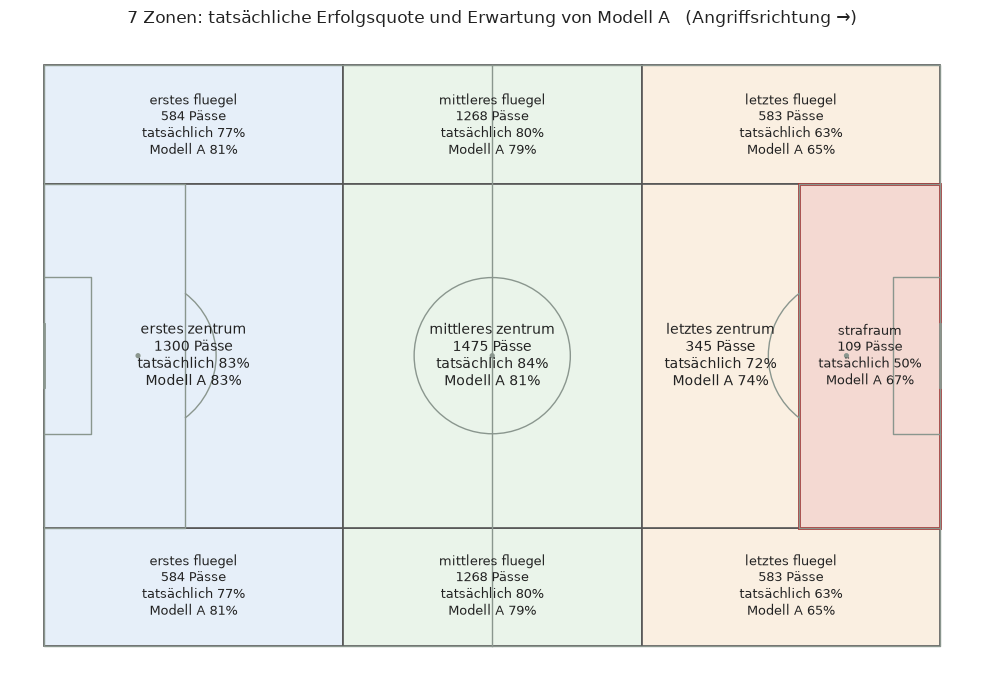

,Pässe,tatsächlich,Modell_A
zone,,,
erstes_fluegel,584,0.769,0.805
erstes_zentrum,1300,0.828,0.829
letztes_fluegel,583,0.633,0.646
letztes_zentrum,345,0.719,0.737
mittleres_fluegel,1268,0.800,0.786
mittleres_zentrum,1475,0.840,0.814
strafraum,109,0.495,0.672


In [5]:
# Jedem Pass seine Zone zuordnen (zone() in modell.py), dann je Zone: tatsächlich vs. Modell A
d["zone"] = zone(d["x"], d["y"])
d["xpass_modell_a"] = vorhersagen["+ Höhe (= Modell A)"]
zonen_tabelle = d.groupby("zone").agg(Pässe=("erfolg", "size"), tatsächlich=("erfolg", "mean"),
                                      Modell_A=("xpass_modell_a", "mean"))


def zonen_grafik(werte, titel):
    # Spielfeld mit den 7 Zonen; werte: dict Zone -> Beschriftung
    # Weißer Hintergrund und dunkle Schrift, damit die Grafik auch im dunklen PyCharm-Design lesbar ist
    schrift = "#222222"
    pitch = Pitch(pitch_type="secondspectrum", pitch_length=105, pitch_width=68, line_color="#8a968e", linewidth=1,
                  pitch_color="white")
    fig, ax = pitch.draw(figsize=(11, 7))
    fig.set_facecolor("white")
    drittel = {"erstes": (-52.5, -DRITTEL_GRENZE), "mittleres": (-DRITTEL_GRENZE, DRITTEL_GRENZE),
               "letztes": (DRITTEL_GRENZE, 52.5)}
    farbe = {"erstes": "#e6eff9", "mittleres": "#eaf4ea", "letztes": "#faefe1"}
    for name, (x0, x1) in drittel.items():
        for y0, y1 in [(STRAFRAUM_Y, 34), (-34, -STRAFRAUM_Y), (-STRAFRAUM_Y, STRAFRAUM_Y)]:
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor=farbe[name], edgecolor="#555", lw=1.2, zorder=0.5))
        mitte_x = (x0 + x1) / 2 if name != "letztes" else (x0 + STRAFRAUM_X) / 2
        ax.text(mitte_x, 0, werte[f"{name}_zentrum"], ha="center", va="center", fontsize=10, zorder=3, color=schrift)
        for y_text in (27, -27):
            ax.text((x0 + x1) / 2, y_text, werte[f"{name}_fluegel"], ha="center", va="center", fontsize=9.5, zorder=3, color=schrift)
    ax.add_patch(Rectangle((STRAFRAUM_X, -STRAFRAUM_Y), 52.5 - STRAFRAUM_X, 2 * STRAFRAUM_Y,
                           facecolor="#f4d9d2", edgecolor="#a33", lw=2, zorder=0.6))
    ax.text((STRAFRAUM_X + 52.5) / 2, 0, werte["strafraum"], ha="center", va="center", fontsize=9.5, zorder=3, color=schrift)
    ax.set_title(titel + "   (Angriffsrichtung →)", fontsize=12, color=schrift)
    return fig, ax


beschriftung = {z: f"{z.replace('_', ' ')}\n{int(r['Pässe'])} Pässe\ntatsächlich {r['tatsächlich']:.0%}\nModell A {r['Modell_A']:.0%}"
                for z, r in zonen_tabelle.iterrows()}
zonen_grafik(beschriftung, "7 Zonen: tatsächliche Erfolgsquote und Erwartung von Modell A")
plt.show()
zonen_tabelle.round(3)

Modell A liegt im Strafraum fast 18 Prozentpunkte daneben (67 % erwartet, 50 % tatsächlich), im Mittelfeld-Zentrum und auf den Flügeln des ersten Drittels um 2–4 Prozentpunkte. Mit dem Ort als Gerade kann das Modell solche Sprünge nicht abbilden.

Dazu kommt: Die Richtung wirkt je nach Ort unterschiedlich. Ein Rückpass vorn ist etwas anderes als ein Rückpass im Aufbau. Das Zonenmodell ergänzt deshalb Wechselwirkungen zwischen Richtung und Drittel.

## 4. Zonenmodell (Hauptmodell): 17 Merkmale

| Gruppe | Merkmal | Definition |
|---|---|---|
| Art | `flanke`, `freistoss`, `abstoss` | 0/1 |
| Ball | `hoch`, `tiefe`, `breite` | wie in Modell A |
| Zonen | `zone_…` | 6 Zonen gegenüber der Bezugszone „mittleres Drittel Zentrum“ (0/1) |
| Richtung je Ort | `zur_mitte` | wie viel näher der Ball auf den ersten 15 m der Spielfeldmitte kommt (−1 bis +1) |
| | `letztes_drittel_x_zurueck` | im letzten Drittel × Rückwärtsanteil max(0, −tiefe) |
| | `letztes_drittel_x_zur_mitte` | im letzten Drittel × `zur_mitte` |
| | `erstes_drittel_x_tiefe` | im ersten Drittel × `tiefe` („Aufbau-Effekt“) |
| Strafraum | `flach_richtung_strafraum` | flacher Pass, dessen Punkt 15 m in Passrichtung im gegnerischen Strafraum liegt (0/1) |

Die Funktionen dafür stehen in `modell.py`. Als Kontrolle rechnen wir Gradient Boosting mit denselben 17 Merkmalen: Findet ein flexibleres Verfahren noch Muster, die die logistische Regression übersieht?

In [6]:
X = zonen_merkmale(d)               # die 17 Merkmale des Zonenmodells (modell.py)


# Kontrolle: ein flexibleres Verfahren mit denselben Merkmalen
def boosting():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300,
                                          min_samples_leaf=40, l2_regularization=1.0)


vorhersagen["Zonenmodell"] = leave_one_match_out(X, y, spiele)
vorhersagen["Boosting (Kontrolle)"] = leave_one_match_out(X, y, spiele, boosting)
d["xpass"] = vorhersagen["Zonenmodell"]     # xPass jedes Passes, von einem Modell, das dieses Spiel nicht kannte
guete(vorhersagen)

,Log-Loss,Brier,AUC
Baseline,0.5210,0.1688,0.5000
Ort + Situation,0.5032,0.1612,0.5771
+ Richtung,0.4437,0.1444,0.7650
+ Höhe (= Modell A),0.3900,0.1246,0.8364
Zonenmodell,0.3763,0.1189,0.8469
Boosting (Kontrolle),0.3761,0.1196,0.8466


- Das Zonenmodell ist besser als Modell A (Log-Loss 0,376 statt 0,390, AUC 0,847 statt 0,836).
- Gradient Boosting mit denselben Merkmalen ist nicht besser. Die logistische Regression reicht also und bleibt interpretierbar.

## 5. Kalibrierung: Stimmen die Prozentzahlen?

Pässe werden nach ihrem xPass gruppiert. Pro Gruppe vergleichen wir den mittleren xPass mit dem Anteil, der tatsächlich ankam. Für die Spielerauswertung (Notebook 03) ist das die wichtigste Eigenschaft, weil wir dort Wahrscheinlichkeiten aufsummieren.

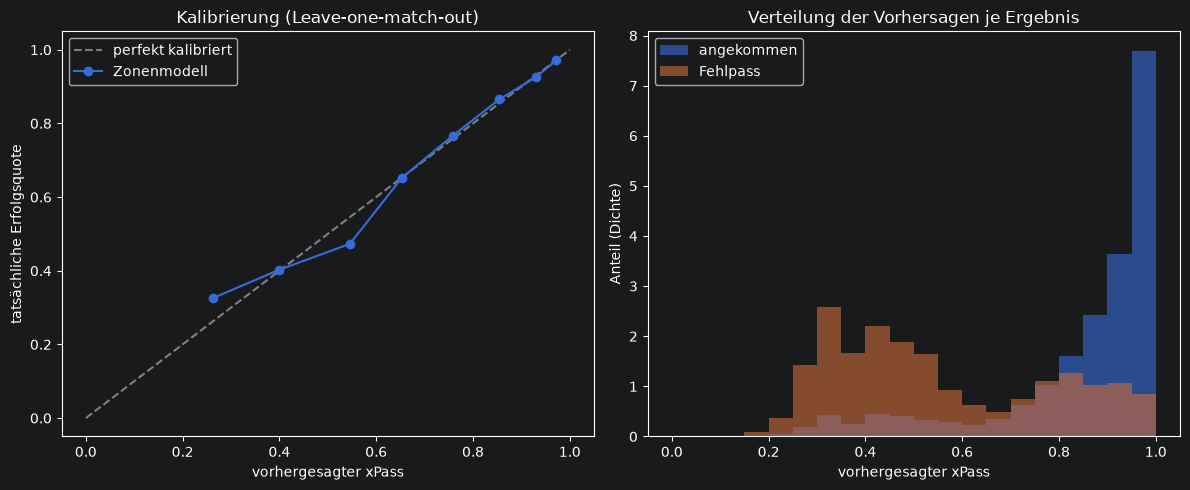

,Pässe,xpass,tatsächlich
xpass,,,
"(0.0, 0.3]",172,0.262,0.326
"(0.3, 0.5]",848,0.399,0.402
"(0.5, 0.6]",296,0.546,0.473
"(0.6, 0.7]",196,0.654,0.653
"(0.7, 0.8]",480,0.758,0.767
"(0.8, 0.9]",1034,0.855,0.866
"(0.9, 0.95]",874,0.930,0.926
"(0.95, 1.0]",1764,0.972,0.971


In [7]:
# Pässe nach xPass gruppieren und je Gruppe vergleichen: vorhergesagt vs. tatsächlich angekommen
gruppen = pd.cut(d["xpass"], [0, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0])
kal = d.groupby(gruppen, observed=True).agg(Pässe=("erfolg", "size"), xpass=("xpass", "mean"),
                                            tatsächlich=("erfolg", "mean"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
# Links: Liegen die Punkte auf der Diagonalen, stimmen die Prozentzahlen
ax1.plot([0, 1], [0, 1], "--", color="grey", label="perfekt kalibriert")
ax1.plot(kal["xpass"], kal["tatsächlich"], "o-", label="Zonenmodell")
ax1.set_xlabel("vorhergesagter xPass"); ax1.set_ylabel("tatsächliche Erfolgsquote")
ax1.set_title("Kalibrierung (Leave-one-match-out)"); ax1.legend()

bins = np.linspace(0, 1, 21)
ax2.hist(d.loc[d["erfolg"] == 1, "xpass"], bins=bins, density=True, alpha=0.6, label="angekommen")
ax2.hist(d.loc[d["erfolg"] == 0, "xpass"], bins=bins, density=True, alpha=0.6, label="Fehlpass")
ax2.set_xlabel("vorhergesagter xPass"); ax2.set_ylabel("Anteil (Dichte)")
ax2.set_title("Verteilung der Vorhersagen je Ergebnis"); ax2.legend()
plt.tight_layout(); plt.show()
kal.round(3)

Die Punkte liegen nah an der Diagonalen. Nur zwei kleine Gruppen weichen deutlicher ab: unter 30 % (26 % vorhergesagt, 33 % tatsächlich) und 50–60 % (55 % gegenüber 47 %). Rechts: Fehlpässe bekommen deutlich niedrigere xPass-Werte (Dichte, damit die viermal häufigeren angekommenen Pässe die Fehlpässe nicht verdecken).

**Kalibrierung je Untergruppe:** mittlerer xPass gegenüber tatsächlicher Quote, im Vergleich mit Modell A.

In [8]:
# Gleicher Vergleich für Untergruppen: jede Zone, beide Ligen, die Passarten
untergruppen = {
    **{f"Zone: {z}": d["zone"] == z for z in sorted(d["zone"].unique())},
    "1. Liga": d["liga"] == 1, "2. Liga": d["liga"] == 2,
    "Flanken": d["flanke"], "Freistöße": d["standard"] == "FREE_KICK", "Abstöße": d["standard"] == "GOAL_KICK",
    "hohe Bälle": d["hoehe"] == "high", "flache Bälle": d["hoehe"] == "flat",
}
pd.DataFrame({
    name: {"Pässe": maske.sum(), "tatsächlich": d.loc[maske, "erfolg"].mean(),
           "Zonenmodell": d.loc[maske, "xpass"].mean(), "Modell A": d.loc[maske, "xpass_modell_a"].mean()}
    for name, maske in untergruppen.items()
}).T.astype({"Pässe": int}).round(3)

,Pässe,tatsächlich,Zonenmodell,Modell A
Zone: erstes_fluegel,584,0.769,0.768,0.805
Zone: erstes_zentrum,1300,0.828,0.827,0.829
Zone: letztes_fluegel,583,0.633,0.633,0.646
Zone: letztes_zentrum,345,0.719,0.719,0.737
Zone: mittleres_fluegel,1268,0.800,0.800,0.786
Zone: mittleres_zentrum,1475,0.840,0.839,0.814
Zone: strafraum,109,0.495,0.505,0.672
1. Liga,1585,0.780,0.782,0.777
2. Liga,4079,0.788,0.787,0.789
Flanken,152,0.283,0.287,0.288


In jeder Zone, in beiden Ligen, bei Flanken, Standards, hohen und flachen Bällen liegt der mittlere xPass des Zonenmodells höchstens 1 Prozentpunkt neben der tatsächlichen Quote. Modell A lag im Strafraum fast 18 Prozentpunkte daneben.

## 6. Was hat das Modell gelernt?

Zum Interpretieren schätzen wir das Modell einmal auf allen Daten mit `statsmodels`, das Konfidenzintervalle liefert.
- **Koeffizient:** Wirkung auf die Log-Odds. Positiv heißt Erfolg wahrscheinlicher, negativ unwahrscheinlicher.
- **Odds-Ratio = e^Koeffizient:** Faktor auf die Chancen (Erfolg : Misserfolg), wenn das Merkmal um 1 steigt, bei sonst gleichen Merkmalen.
- **Zonen** gelten im Vergleich zur Bezugszone „mittleres Drittel Zentrum“; bei Wechselwirkungen kommt der Zuschlag im ersten bzw. letzten Drittel hinzu.

In [9]:
# Zonenmodell einmal auf allen Pässen schätzen; statsmodels liefert auch Konfidenzintervalle und p-Werte
logit = sm.Logit(y, sm.add_constant(X)).fit(disp=False)
pd.DataFrame({
    "Koeffizient": logit.params, "KI 2,5 %": logit.conf_int()[0], "KI 97,5 %": logit.conf_int()[1],
    "Odds-Ratio": np.exp(logit.params), "p-Wert": logit.pvalues,
}).round(3)

,Koeffizient,"KI 2,5 %","KI 97,5 %",Odds-Ratio,p-Wert
const,2.418,2.099,2.736,11.220,0.000
flanke,-0.595,-1.056,-0.135,0.551,0.011
freistoss,0.289,-0.120,0.698,1.335,0.166
abstoss,-0.243,-0.771,0.286,0.785,0.368
hoch,-1.910,-2.081,-1.740,0.148,0.000
tiefe,-1.004,-1.220,-0.789,0.366,0.000
breite,0.713,0.389,1.037,2.040,0.000
zone_erstes_zentrum,1.209,0.725,1.692,3.349,0.000
zone_erstes_fluegel,0.579,0.086,1.073,1.785,0.021
zone_mittleres_fluegel,-0.327,-0.564,-0.090,0.721,0.007


**Lesebeispiele:**
- **Hoher Ball:** Odds-Ratio ≈ 0,15. Aus Chancen von 9 : 1 (90 %) werden etwa 1,3 : 1 (57 %). Das Modell ist linear in den Log-Odds, nicht in Prozent: Wie viele Prozentpunkte ein Merkmal kostet, hängt davon ab, wo man startet.
- **Flacher Pass Richtung Strafraum:** Odds-Ratio ≈ 0,25, das zweitstärkste Risiko.
- **Zonen:** Im ersten Drittel im Zentrum sind die Chancen 3,3-mal so hoch wie in der Bezugszone, im Strafraum nur 0,36-mal.
- **Rückpass:** Außerhalb des letzten Drittels ist ein Rückpass deutlich sicherer (`tiefe` negativ, Rückpass = −1). Im letzten Drittel nimmt `letztes_drittel_x_zurueck` diesen Vorteil fast vollständig weg.
- **Aufbau-Effekt:** Im ersten Drittel sind Quer- und Rückpässe fast risikolos (Zonen-Gewicht positiv); `erstes_drittel_x_tiefe` sorgt dafür, dass Pässe in die Tiefe diesen Bonus nicht bekommen.

Alle Richtungen sind fußballerisch plausibel.

## 7. Beispielszenen

Typische Pässe aus dem laufenden Spiel zwischen den Strafräumen:
1. ein sehr sicherer Pass
2. ein sehr riskanter Pass
3. eine „Überraschung“: Das Modell war sich sicher, trotzdem ein Fehlpass

Blauer Pfeil: Pass bis zum Endpunkt laut kloppy. Roter Pfeil: Richtung eines Fehlpasses (10 m), denn bei Fehlpässen gibt es keinen Endpunkt.

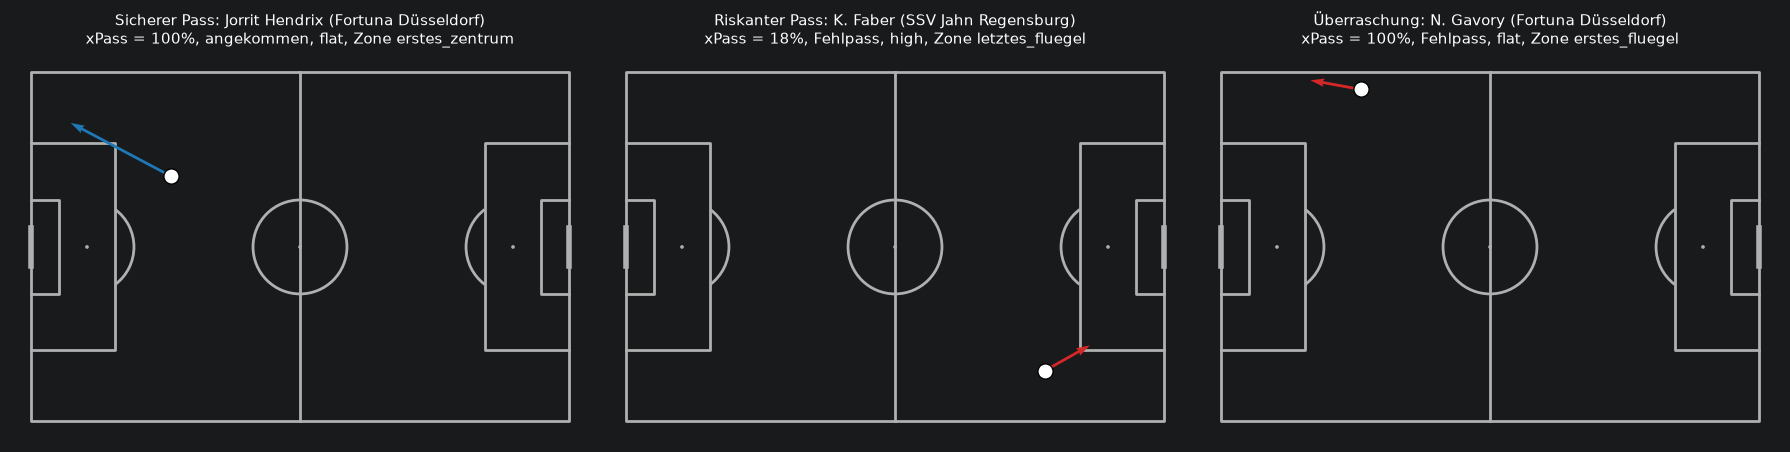

In [10]:
offen = d[(d["standard"] == "OPEN_PLAY") & (d["x"].abs() < 35)]
# Drei Szenen: höchster xPass (angekommen), niedrigster xPass, höchster xPass trotz Fehlpass
szenen = {
    "Sicherer Pass": offen[offen["erfolg"] == 1].sort_values("xpass", ascending=False).iloc[0],
    "Riskanter Pass": offen.sort_values("xpass").iloc[0],
    "Überraschung": offen[offen["erfolg"] == 0].sort_values("xpass", ascending=False).iloc[0],
}
pitch = Pitch(pitch_type="secondspectrum", pitch_length=105, pitch_width=68)
fig, axes = pitch.draw(nrows=1, ncols=3, figsize=(18, 5))
for ax, (titel, s) in zip(axes, szenen.items()):
    w = np.radians(s["play_angle"])
    if s["erfolg"] == 1:
        pitch.arrows(s["x"], s["y"], s["end_x"], s["end_y"], ax=ax, color="tab:blue", width=2)
    else:
        # Fehlpass hat keinen Endpunkt, deshalb Pfeil 10 m in Passrichtung
        pitch.arrows(s["x"], s["y"], s["x"] + 10 * np.cos(w), s["y"] - 10 * np.sin(w), ax=ax, color="tab:red", width=2)
    pitch.scatter(s["x"], s["y"], ax=ax, s=120, color="white", edgecolors="black", zorder=3)
    ergebnis = "angekommen" if s["erfolg"] == 1 else "Fehlpass"
    ax.set_title(f"{titel}: {s['player']} ({s['team']})\nxPass = {s['xpass']:.0%}, {ergebnis}, {s['hoehe']}, Zone {s['zone']}", fontsize=11)
plt.show()

**Lesart:**
1. **Sicherer Pass:** flacher Rückpass im eigenen Drittel, ohne Risiko nach außen gespielt: xPass 100 %. Plausibel, normalerweise ein sicherer Ball im Spielaufbau.
2. **Riskanter Pass:** hoher Ball vom rechten Flügel in den Strafraum: xPass 18 %. Plausibel, im Strafraum stehen viele Gegner, hohe Bälle werden im Kopfballduell entschieden.
3. **Überraschung:** flacher Rückpass an der Seitenlinie im eigenen Drittel, xPass fast 100 %, trotzdem landet der Ball beim Gegner. Für ein Modell ohne Gegnerpositionen ist dieser Pass sicher; ob ein Gegner nah am Passgeber stand oder in den Passweg lief, kann es nicht wissen. Genau hier setzt die Erweiterung mit Tracking-Daten an (Notebook 04).

## 8. Vorhersagen speichern

Jeder Pass mit seinem xPass aus dem Zonenmodell (out-of-sample), als Grundlage für die Spieler- und Teamauswertung in Notebook 03.

In [11]:
spalten = ["match_id", "liga", "event_id", "period", "t", "team_id", "team", "player_id", "player",
           "standard", "flanke", "hoehe", "x", "y", "zone", "play_angle", "erfolg", "xpass", "xpass_modell_a"]
d[spalten].to_csv(ROOT / "data" / "vorhersagen_zonen.csv", index=False)     # Notebook 03 liest diese Datei
print("gespeichert: data/vorhersagen_zonen.csv")

gespeichert: data/vorhersagen_zonen.csv


## Fazit

- **Weg:** Baseline (Log-Loss 0,521) → Ort + Situation (0,503) → + Richtung (0,444) → + Höhe = Modell A (0,390) → Zonenmodell (0,376).
- **Wie gut ist das Modell?** Out-of-sample (Leave-one-match-out) Log-Loss 0,376 statt 0,521 ohne Modell, AUC 0,847. Gut kalibriert: In jeder Zone, Liga und Passart liegt der mittlere xPass höchstens 1 Prozentpunkt neben der tatsächlichen Quote. Die Gewichte sind fußballerisch plausibel.
- **Ausgabe:** `data/vorhersagen_zonen.csv` mit dem xPass jedes der 5.664 Pässe.

## Grenzen

- **Keine Gegnerpositionen:** Restfehler wie in Szene 3 entstehen vor allem dadurch. Gegnerdruck und Passweg ergänzt Notebook 04 aus den Tracking-Daten.
- **Richtung laut DFL:** Bei abgefälschten Bällen könnte `PlayAngle` eher zum Abfangpunkt zeigen (leichte Leakage). Notebook 04 bestimmt die Richtung aus dem Ballweg.
- **Harte Zonengrenzen:** Ein Meter vor oder hinter einer Grenze kann das Ausgangsniveau ändern.
- **Kleine Datenbasis:** 7 Spiele, davon 2 aus der 1. Liga.